<a href="https://colab.research.google.com/github/alexandrescruz/analise-cafeterias-chicago/blob/main/Analise_cafeterias_chicago.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Onde abrir 4 novas cafeterias em Chicago? Uma análise geoespacial com K-Means

**Pergunta de negócio:** uma rede de cafeterias quer abrir **4 novas lojas** em Chicago e acredita que regiões com muitas bibliotecas públicas concentram o público que ela busca (estudantes, pessoas trabalhando remotamente, leitores).

**Hipótese:** pontos próximos de *aglomerados* de bibliotecas são bons candidatos para as novas lojas.

**Abordagem**
1. Coletar a localização das bibliotecas públicas pela API de dados abertos da Prefeitura de Chicago.
2. Converter latitude/longitude para quilômetros, para que as distâncias calculadas sejam reais.
3. Agrupar as bibliotecas em 4 regiões com **K-Means** e avaliar a qualidade desse agrupamento.
4. Para cada região, comparar dois candidatos: o **centroide** (menor distância média até as bibliotecas da região) e o **ponto de maior densidade** (a biblioteca com mais bibliotecas vizinhas num raio caminhável).
5. Visualizar tudo num mapa interativo com **Folium**.

**Ferramentas:** `requests` e `pandas` (coleta e tratamento), `numpy`, `scikit-learn` (K-Means e silhueta), `matplotlib` (gráficos) e `folium` (mapa).
*Projeto desenvolvido durante a IBM Data Science Professional Certificate (Coursera).*

In [ ]:
!pip install -q folium

## 1. Coleta dos dados

A API retorna os dados em `data` e a descrição das colunas em `meta`. Em vez de acessar as colunas por posição fixa (ex.: `linha[8]`, que quebra se a prefeitura mudar a ordem), localizamos as colunas **pelo nome** usando os metadados.

In [ ]:
import requests
import pandas as pd
import numpy as np

URL = "https://data.cityofchicago.org/api/views/x8fc-8rcq/rows.json?accessType=DOWNLOAD"

resposta = requests.get(URL, timeout=30)
resposta.raise_for_status()
dados = resposta.json()
registros =[]

for linha in dados["data"]:
  latitude = float(linha[17][1])
  longitude = float(linha[17][2])
  nome = linha[8]
  registros.append({"nome": nome, "latitude": latitude, "longitude": longitude})

libs_df = pd.DataFrame(registros)
print(f"{len(libs_df)} bibliotecas carregadas")
#libs_df.head()
#libs_df.describe()
#libs_df.duplicated().sum()
#libs_df.isnull().sum()



82 bibliotecas carregadas


## 2. Limpeza e checagem rápida

Removemos duplicatas e qualquer coordenada fora dos limites aproximados de Chicago (proteção contra erros de cadastro).

In [ ]:
antes = len(libs_df)
libs_df = libs_df.drop_duplicates(subset=["latitude", "longitude"])
libs_df = libs_df[libs_df["latitude"].between(41.6, 42.1) &
                  libs_df["longitude"].between(-88.0, -87.5)].reset_index(drop=True)
print(f"Registros removidos: {antes - len(libs_df)} | restantes: {len(libs_df)}")
libs_df.describe()

Registros removidos: 0 | restantes: 82


,latitude,longitude
count,82.000000,82.000000
mean,41.847521,-87.678917
std,0.095450,0.064562
min,41.657198,-87.814200
25%,41.778886,-87.722811
50%,41.851856,-87.673400
75%,41.925270,-87.638683
max,42.006822,-87.533599


## 3. De graus para quilômetros

O K-Means usa distância euclidiana. Em graus, isso distorce o resultado: na latitude de Chicago (~42°), **1° de longitude vale cerca de 83 km, enquanto 1° de latitude vale cerca de 111 km**. Sem corrigir, o algoritmo "acha" que pontos a leste/oeste estão mais próximos do que realmente estão.

Projetamos as coordenadas num plano local em km (projeção equiretangular, precisa o suficiente para a escala de uma cidade).

In [ ]:
KM_POR_GRAU_LAT = 110.57
LAT0 = libs_df["latitude"].mean()
LON0 = libs_df["longitude"].mean()
KM_POR_GRAU_LON = 111.32 * np.cos(np.radians(LAT0))

def para_km(lat, lon):
    return np.column_stack([(lon - LON0) * KM_POR_GRAU_LON,
                            (lat - LAT0) * KM_POR_GRAU_LAT])

def para_graus(xy_km):
    lon = xy_km[:, 0] / KM_POR_GRAU_LON + LON0
    lat = xy_km[:, 1] / KM_POR_GRAU_LAT + LAT0
    return lat, lon

X = para_km(libs_df["latitude"].values, libs_df["longitude"].values)
print(f"1° de longitude ≈ {KM_POR_GRAU_LON:.1f} km | 1° de latitude ≈ {KM_POR_GRAU_LAT:.1f} km")

1° de longitude ≈ 82.9 km | 1° de latitude ≈ 110.6 km


## 4. Quantos grupos os dados sugerem?

O negócio já definiu **k = 4** (quatro lojas). Mesmo assim, vale verificar o que os dados dizem, usando o **método do cotovelo** (inércia) e o **coeficiente de silhueta** (quanto mais perto de 1, mais bem separados os grupos).

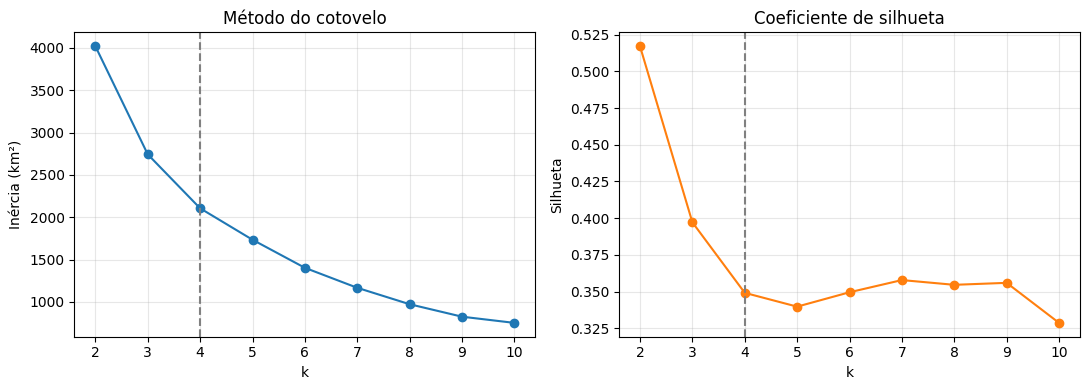

Silhueta com k=4: 0.35


In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = range(2, 11)
inercias, silhuetas = [], []
for k in ks:
    modelo = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inercias.append(modelo.inertia_)
    silhuetas.append(silhouette_score(X, modelo.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(ks, inercias, marker="o"); ax1.set_title("Método do cotovelo")
ax1.set_xlabel("k"); ax1.set_ylabel("Inércia (km²)")
ax2.plot(ks, silhuetas, marker="o", color="tab:orange"); ax2.set_title("Coeficiente de silhueta")
ax2.set_xlabel("k"); ax2.set_ylabel("Silhueta")
for ax in (ax1, ax2):
    ax.axvline(4, ls="--", color="gray"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"Silhueta com k=4: {silhuetas[2]:.2f}")

**Leitura:** as bibliotecas de Chicago estão espalhadas de forma relativamente uniforme pela cidade (é uma rede pública pensada para cobrir todos os bairros), então nenhum valor de k produz grupos *muito* separados. A silhueta moderada é esperada e significa que o K-Means aqui está mais **dividindo a cidade em 4 regiões de atendimento** do que encontrando "ilhas" naturais. Isso é coerente com o objetivo de negócio, mas é importante deixar claro na conclusão.

## 5. K-Means com k = 4

In [ ]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
libs_df["cluster"] = kmeans.fit_predict(X)

cent_lat, cent_lon = para_graus(kmeans.cluster_centers_)
dist_centroide = np.linalg.norm(X - kmeans.cluster_centers_[libs_df["cluster"]], axis=1)
libs_df["dist_centroide_km"] = dist_centroide.round(2)

## 6. Dois candidatos por região

- **Centroide:** minimiza a distância média até todas as bibliotecas do grupo, mas pode cair num lugar sem movimento (um parque, um pátio ferroviário).
- **Ponto de maior densidade:** a biblioteca que tem **mais outras bibliotecas num raio de 2 km** (~25 min a pé). Está sempre num endereço real e responde mais diretamente à hipótese "áreas com mais bibliotecas ao redor".

In [ ]:
RAIO_KM = 2.0
from scipy.spatial.distance import cdist

D = cdist(X, X)                                  # matriz de distâncias em km
libs_df["vizinhas_2km"] = (D <= RAIO_KM).sum(axis=1) - 1

resumo = []
for c in range(K):
    grupo = libs_df[libs_df["cluster"] == c]
    denso = grupo.sort_values(["vizinhas_2km", "dist_centroide_km"],
                              ascending=[False, True]).iloc[0]
    mais_proxima = grupo.loc[grupo["dist_centroide_km"].idxmin()]
    resumo.append({
        "regiao": c,
        "bibliotecas": len(grupo),
        "dist_media_km": round(grupo["dist_centroide_km"].mean(), 2),
        "pct_ate_2km_do_centroide": f"{(grupo['dist_centroide_km'] <= RAIO_KM).mean():.0%}",
        "centroide": f"{cent_lat[c]:.5f}, {cent_lon[c]:.5f}",
        "biblioteca_mais_proxima_do_centroide": mais_proxima["nome"],
        "ponto_denso (biblioteca)": denso["nome"],
        "vizinhas_em_2km": int(denso["vizinhas_2km"]),
        "denso_lat": denso["latitude"], "denso_lon": denso["longitude"],
    })

resumo_df = pd.DataFrame(resumo).sort_values("vizinhas_em_2km", ascending=False)
resumo_df.drop(columns=["denso_lat", "denso_lon"])

,regiao,bibliotecas,dist_media_km,pct_ate_2km_do_centroide,centroide,biblioteca_mais_proxima_do_centroide,ponto_denso (biblioteca),vizinhas_em_2km
2,2,23,4.74,17%,"41.79423, -87.67146",Sherman Park,Canaryville,3
0,0,19,4.74,11%,"41.96869, -87.73473",Mayfair,West Belmont,2
1,1,16,5.20,0%,"41.71356, -87.61070",Pullman,Brainerd,2
3,3,24,4.28,12%,"41.89198, -87.68736",Manning,West Town,2


## 7. Mapa interativo

Use o controle de camadas (canto superior direito) para ligar/desligar cada grupo. Clique nos marcadores para ver nomes e detalhes. Os círculos mostram o raio de 2 km em volta de cada ponto de maior densidade.

In [ ]:
import folium

CORES = ["green", "blue", "purple", "orange", "darkred", "cadetblue"]

m = folium.Map(location=[LAT0, LON0], zoom_start=11, tiles='https://tile.osm.ch/switzerland/{z}/{x}/{y}.png',attr='My Data Attribution')

camada_bibs = {c: folium.FeatureGroup(name=f"Bibliotecas – região {c}") for c in range(K)}
for _, b in libs_df.iterrows():
    folium.CircleMarker(
        location=[b["latitude"], b["longitude"]], radius=5,
        color=CORES[b["cluster"]], fill=True, fill_opacity=.8,
        popup=f"<b>{b['nome']}</b><br>Região {b['cluster']}<br>"
              f"{b['vizinhas_2km']} bibliotecas em 2 km",
    ).add_to(camada_bibs[b["cluster"]])
for g in camada_bibs.values():
    g.add_to(m)

camada_cent = folium.FeatureGroup(name="Centroides (K-Means)")
camada_densos = folium.FeatureGroup(name="Pontos de maior densidade")
for r in resumo:
    c = r["regiao"]
    folium.Marker([cent_lat[c], cent_lon[c]],
                  icon=folium.Icon(color="red", icon="star"),
                  popup=f"<b>Centroide região {c}</b><br>{r['bibliotecas']} bibliotecas<br>"
                        f"Distância média: {r['dist_media_km']} km").add_to(camada_cent)
    folium.Marker([r["denso_lat"], r["denso_lon"]],
                  icon=folium.Icon(color="black", icon="coffee", prefix="fa"),
                  popup=f"<b>Candidato região {c}</b><br>Perto de: {r['ponto_denso (biblioteca)']}<br>"
                        f"{r['vizinhas_em_2km']} bibliotecas em 2 km").add_to(camada_densos)
    folium.Circle([r["denso_lat"], r["denso_lon"]], radius=RAIO_KM * 1000,
                  color=CORES[c], fill=True, fill_opacity=.07).add_to(camada_densos)
camada_cent.add_to(m); camada_densos.add_to(m)

folium.LayerControl(collapsed=False).add_to(m)
m.fit_bounds([[libs_df.latitude.min(), libs_df.longitude.min()],
              [libs_df.latitude.max(), libs_df.longitude.max()]])
m.save("mapa_cafeterias_chicago.html")   # arquivo para compartilhar / publicar no GitHub Pages
m

## 8. Conclusões

- As bibliotecas foram divididas em **4 regiões de atendimento**; a tabela da seção 6 mostra, para cada uma, quantas bibliotecas atende e a distância média até o centroide.
- Os **pontos de maior densidade** são os candidatos mais fortes para a hipótese do projeto: ficam em endereços reais e têm o maior número de bibliotecas a uma distância caminhável.
- Os **centroides** servem como referência de "centro geográfico" de cada região e ajudam a ver se a loja ficaria equidistante do público de toda a região.

## 9. Limitações e próximos passos

Biblioteca por perto não garante venda. Para transformar a análise numa recomendação de negócio, os próximos passos seriam:

1. **Concorrência:** incluir cafeterias existentes (ex.: Foursquare / OpenStreetMap) e penalizar áreas saturadas.
2. **Demanda real:** cruzar com população por bairro, universidades, escritórios e fluxo de passageiros das estações do CTA (também disponíveis no portal de dados de Chicago).
3. **Peso das bibliotecas:** usar visitas mensais por biblioteca (o portal publica esse dado) para dar mais peso às mais movimentadas (`sample_weight` no K-Means).
4. **Custo:** considerar aluguel comercial por região.